### Integrantes
- Carlos Alberto Castro Valencia
- John Alexis Cardona Zapata
- Kevin Velasquez Giraldo

# 0. Importación de la data

In [27]:
# Se conecta al Google Drive para extraer la base de datos
#from google.colab import drive
#drive.mount('/content/drive/')
#
## Lista los contenidos de MyDrive en Google Drive valdiando que exista la base de datos
#!ls /content/drive/MyDrive/Colab\ Notebooks/Inteligencia\ Artificial

In [28]:
# Importa la base de datos al proyecto
import pandas as pd
from pathlib import Path


file_path = Path(r'.\DataBase\equipo_03_base_credito_ia.xlsx')
df = pd.read_excel(file_path)

print(df.count(axis=1))
display(df.head())

0       28
1       28
2       28
3       28
4       28
        ..
1210    28
1211    28
1212    28
1213    28
1214    27
Length: 1215, dtype: int64


,Cliente,Mora30,Mora60,Segmento,SECTOR,REGCONS,FDESEM,Ingresos,PersonasCargo,Gastos,...,Tipo_Vivienda,Calificación Superfinanciera,CalificaciónSistema Financiero,MoraMaxima 12 meses,%Deuda Actual Sistema Financiero,MoraMaxima 12 meses.1,Experiencia Financiera,Antigüedad en el Sistema Financiero,Numero de creditos vigentes,Semaforo_Comite_Riesgo
0,141,1,0,MDO,PERSONAS NATURALES,ESPECIAL,2013-10-02 00:00:00,1.280000,0.0,0.409700,...,FAMILIAR,A,857,47,0.282593,47,1,20,0,BAJO
1,46,0,0,MDO,PERSONAS NATURALES,NORTE,2013-05-08 00:00:00,1.200000,1.0,0.308000,...,FAMILIAR,B,666,0,0.351257,0,1,5,0,BAJO
2,121,0,0,MDO,PERSONAS NATURALES,OCCIDENTE,2015-02-23 00:00:00,1.244000,0.0,0.386000,...,FAMILIAR,A,836,30,0.573720,30,0,60,0,BAJO
3,596,0,0,STD,PERSONAS NATURALES,OCCIDENTE,2014-12-16 00:00:00,0.764196,0.0,0.367636,...,FAMILIAR,A,809,17,0.701327,17,1,3,0,MEDIO
4,651,0,0,MDO,PERSONAS NATURALES,OCCIDENTE,2015-10-28 00:00:00,1.125000,0.0,0.308000,...,ALQUILADA,A,778,0,0.919884,0,0,0,0,BAJO


# 1- Contexto (Personalización)

Bancolombia es una institución financiera líder en Colombia con presencia internacional y una amplia gama de servicios para personas, empresas y pymes.

Este proyecto es una iniciativa para Bancolombia S.A.S., especificamente para el entorno de cartera, la cual nos dio como objetivo principal para el Q4 del 2026, desarrollar un modelo predictivo que identifique a los clientes propensos a incurrir en mora de 30 días (Mora30) o mora de 60 días (Mora60) en el pago de sus créditos.
<a href="https://logo-teka.com/es/bancolombia/"><img src="https://logo-teka.com/wp-content/uploads/2026/05/bancolombia-logo.png" alt="PNG logo Bancolombia" style="max-width:200px;" /></a>

## Consultura
![Logo Orbis Insights](https://github.com/VelasquezG/TallerIA/blob/main/assets/logo_Orbis_Insights.jpg?raw=true)

**Orbis Insights** es una firma especializada en **análisis de información, inteligencia estratégica e investigación**, orientada a transformar información dispersa y compleja en conocimiento claro, relevante y accionable.

**Orbis Insights** representa una filosofía de trabajo basada en **ver el panorama completo, interpretar lo relevante y convertirlo en conocimiento para la toma de decisiones**.

**Paleta de Colores**
- `#1A365D`
- `#2C7A7B`
- `#A0AEC0`
- `#4FD1C5`

In [29]:
# Definir la paleta de colores de la consultora para uso en los gráficos
paleta_consultora = ['#1A365D', '#2C7A7B', '#A0AEC0', '#4FD1C5']

# 2- ¿Problema? (Focalizado a predecir la mora)

¿ Se puede mejorar el sistema crediticio de Bancolombia mediante un modelo predictivo que identifique clientes con alta probabilidad de caer en mora (30 o 60 días), utilizando únicamente datos financieros ?

# 3- Datos (metadatos)
##          * Politicas empresariales.

* P1 - Unidad de medida
  - `Ingresos`, `Ingresos_Totales` y `Gastos` deben corresponder al mismo periodo y unidad antes de compararse. Si `Gastos` está en pesos, convertirlo a SMMLV con el SMMLV del periodo.

* P2 — Fechas y formato
  - `FDESEM` representa la fecha de desembolso. Convertirla con `pd.to_datetime(errors='coerce')`, validar fechas no convertibles y mantenerla como tipo fecha para ordenar.
  - La presentación estándar de las fechas es `dd/MM/yyyy`.

* P3 — Rangos y coherencia de variables
  - `Ingresos`, `Ingresos_Totales` y `Gastos` deben ser numéricos y no negativos. Los negativos se marcan como inconsistencias para revisión.
  - `Ingresos_Totales` normalmente debe ser mayor o igual que `Ingresos`. Si es menor, revisar si ambas variables tienen el mismo periodo, alcance y definición; no corregir automáticamente.
  - `%Deuda Actual Sistema Financiero` debe estar entre 0 y 1; confirmar primero que no esté expresado como porcentaje de 0 a 100.
  - `Antigüedad en el Sistema Financiero` debe ser un número de años no negativo y compatible con la fecha de desembolso y la fecha de consulta. Los valores extremos se investigan, no se descartan por un máximo arbitrario.
  - `Numero de creditos vigentes` debe ser entero no negativo. Los valores no enteros, negativos o faltantes se reportan según su causa.
  - `Edad` es un dato numérico que no puede ser negativo ni superar los 100 años; los valores fuera de este rango se marcan como faltantes para revisión, sin imputarlos automáticamente.
  - `Mora60 = 1` implica `Mora30 = 1` únicamente cuando ambas etiquetas pertenecen al mismo periodo; las contradicciones se reportan y se excluyen del entrenamiento afectado.


##          * Reglas de negocio.

* R1 - Eliminación de Variables Redundantes (MoraMaxima 12 meses.1):

 La variable MoraMaxima 12 meses.1 es una duplicación exacta de MoraMaxima 12 meses. Se procederá a eliminar MoraMaxima 12 meses.1 para optimizar la base de datos y evitar redundancias.

* R2 - Gestión de Registros Duplicados:

Se identificarán y eliminarán los registros que sean completamente duplicados en la base de datos. Si existen casos de Cliente con múltiples registros pero con diferencias en alguna variable (ej., Semaforo_Comite_Riesgo), estos serán aislados y presentados al área de negocio para su validación antes de cualquier acción.

* R3 - Normalización de la Variable Edad:

 Los registros de Edad fuera del rango esperado (18-100 años) se considerarán inconsistentes. Para estos casos, la Edad se imputará utilizando la mediana de las edades válidas, que es una medida robusta ante valores atípicos y ayuda a mantener la distribución central de la variable.

* R4 - Manejo de Outliers en Numero de creditos vigentes:

 Aunque se pueden identificar valores atípicos en Numero de creditos vigentes (ej., 25 créditos), estos no se eliminarán automáticamente sin una validación de negocio. Se aplicará un filtro para el análisis, considerando un máximo de 5 créditos vigentes, para excluir temporalmente los outliers sin descartar su posible relevancia.

* R5 - Estandarización de FDESEM:

 La variable FDESEM será estandarizada a un formato de fecha datetime (dd/MM/yyyy). Se verificarán y reportarán los valores que no puedan ser convertidos. Esta estandarización permite una manipulación y análisis temporal coherente.

* R6 - Imputación de Tipo_Vivienda:

 Los valores faltantes en la variable categórica Tipo_Vivienda serán imputados con la categoría 'SIN_INFORMACION'. Esta estrategia preserva la información de ausencia de dato sin introducir sesgos por imputación con categorías existentes.

* R7 - Imputación de SECTOR:

 La variable SECTOR presentó 21 valores faltantes. Para su manejo, y dado que es una variable categórica, se imputarán los valores nulos con la categoría 'SIN_INFORMACION'. Esto permite preservar la información de ausencia de dato y evitar introducir sesgos por imputación con categorías existentes.

* R8 - Filtrado y Segmentación de Ingresos:

 Se aplicará un proceso de filtrado a la variable Ingresos para centrarse en el rango intercuartílico (entre el primer cuartil P25 y el tercer cuartil P75) de la distribución. Esto permitirá eliminar outliers y segmentar los datos de ingresos en un rango más representativo para el análisis. Los registros fuera de este rango serán considerados valores atípicos y se analizarán por separado.

# 4- EDA (Análisis exploratorio)

## Boxplots para todas las columnas numéricas
A continuación, se generarán boxplots para cada columna numérica en el DataFrame df para facilitar la identificación de la distribución de los datos y la presencia de valores atípicos.

c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'hori

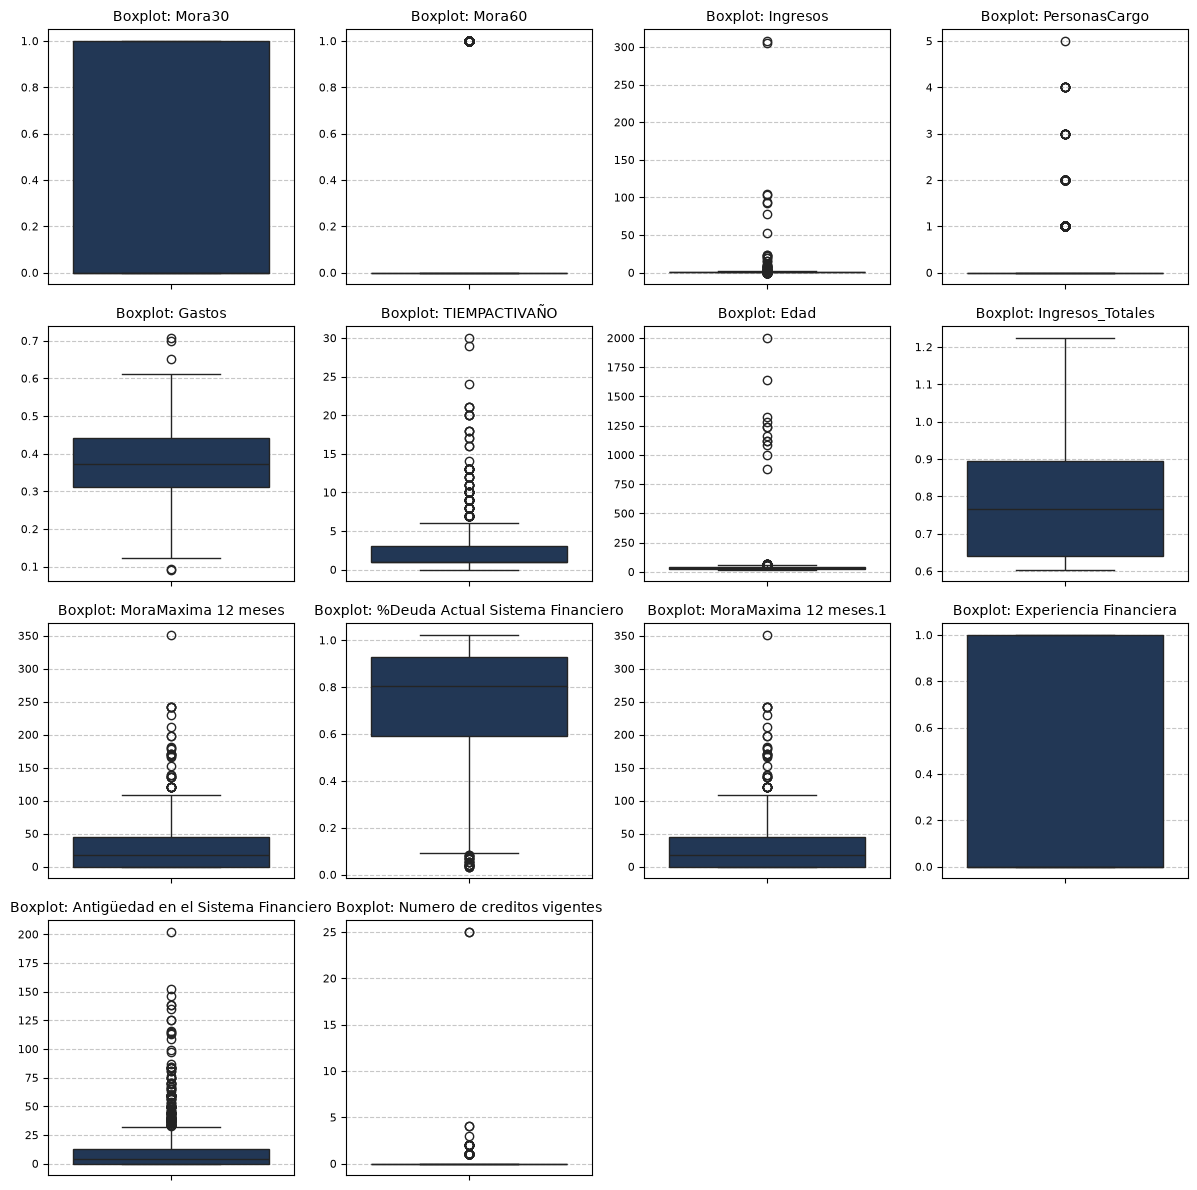

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Seleccionar solo las columnas numéricas
numerical_cols = df.select_dtypes(include=['number']).columns

# Excluir la columna 'Cliente' si es numérica, ya que generalmente es un ID y no se presta para boxplots significativos.
if 'Cliente' in numerical_cols:
    numerical_cols = numerical_cols.drop('Cliente')

# Calcular el número de filas y columnas para la matriz de boxplots
num_plots = len(numerical_cols)
num_cols = 4 # Número deseado de columnas en la cuadrícula
num_rows = int(np.ceil(num_plots / num_cols))

plt.figure(figsize=(num_cols * 3, num_rows * 3)) # Ajustar el tamaño total de la figura

for i, column in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1) # Crear un subplot para cada columna
    sns.boxplot(y=df[column].dropna(), color=paleta_consultora[0])
    plt.title(f'Boxplot: {column}', fontsize=10)
    plt.ylabel('') # Ocultar etiqueta y para no saturar
    plt.tick_params(axis='y', labelsize=8) # Reducir tamaño de ticks
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout() # Ajustar el diseño para evitar superposiciones
plt.show()

## R1 MoraMaxima 12 meses
Se identificó que las variables MoraMaxima 12 meses y MoraMaxima 12 meses.1 contienen exactamente la misma información para los 1.215 registros analizados. La comparación elemento a elemento no presentó diferencias. Por lo tanto, MoraMaxima 12 meses.1 se considera una variable redundante y se elimina de la base de datos para evitar duplicidad de información, manteniendo únicamente MoraMaxima 12 meses.

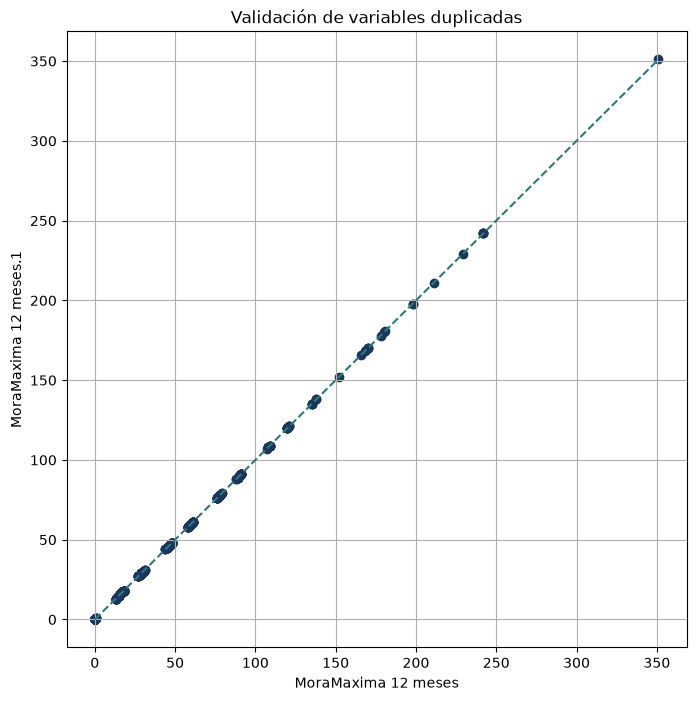

¿Son exactamente iguales?: True
Diferencias encontradas: 0


In [31]:
columna_redundante = 'MoraMaxima 12 meses.1'

# Verificar si la columna existe en el DataFrame
if columna_redundante in df.columns:
    x = df["MoraMaxima 12 meses"]
    y = df[columna_redundante]

    plt.figure(figsize=(8, 8))

    plt.scatter(x, y, color=paleta_consultora[0])

    # Línea de igualdad
    minimo = min(x.min(), y.min())
    maximo = max(x.max(), y.max())

    plt.plot(
        [minimo, maximo],
        [minimo, maximo],
        linestyle="--",
        color=paleta_consultora[1]
    )

    plt.title("Validación de variables duplicadas")
    plt.xlabel("MoraMaxima 12 meses")
    plt.ylabel("MoraMaxima 12 meses.1")

    plt.grid(True)
    plt.show()

    # Validación numérica
    print("¿Son exactamente iguales?:", x.equals(y))
    print("Diferencias encontradas:", (x != y).sum())
else:
    print(f"La columna '{columna_redundante}' no se encuentra en el DataFrame. Es probable que ya haya sido eliminada.")
    print("Como se mencionó en la regla R1, esta columna es redundante y se eliminó previamente.")

In [32]:
# Despues de la validación se procede a eliminar la columna MoraMaxima 12 meses.1
columna2 = 'MoraMaxima 12 meses.1' # Definir columna2 explicitamente
df = df.drop(columns=[columna2])
print(f"Columna '{columna2}' Se ha eliminado. Columnas actuales: {df.columns.tolist()}")

Columna 'MoraMaxima 12 meses.1' Se ha eliminado. Columnas actuales: ['Cliente', 'Mora30', 'Mora60', 'Segmento', 'SECTOR', 'REGCONS', 'FDESEM', 'Ingresos', 'PersonasCargo', 'Gastos', 'TIEMPACTIVAÑO', 'OCUPACIÓN', 'TIPCONTRATO', 'Edad', 'Estado_Civil', 'Género', 'Ingresos_Totales', 'Nivel_Academico', 'Tipo_Vivienda', 'Calificación Superfinanciera', 'CalificaciónSistema Financiero', 'MoraMaxima 12 meses', '%Deuda Actual Sistema Financiero', 'Experiencia Financiera', 'Antigüedad en el Sistema Financiero', 'Numero de creditos vigentes', 'Semaforo_Comite_Riesgo']


## R2 Duplicados

Se identificaron 1.215 registros, de los cuales 6 eran completamente duplicados. Estos fueron eliminados, ya que no aportaban información adicional.

La base quedó con 1.209 registros.

Clientes duplicados:
Cliente
999     2
864     2
149     2
315     2
1127    2
1134    2
343     2
Name: count, dtype: int64

Cantidad de clientes duplicados: 7


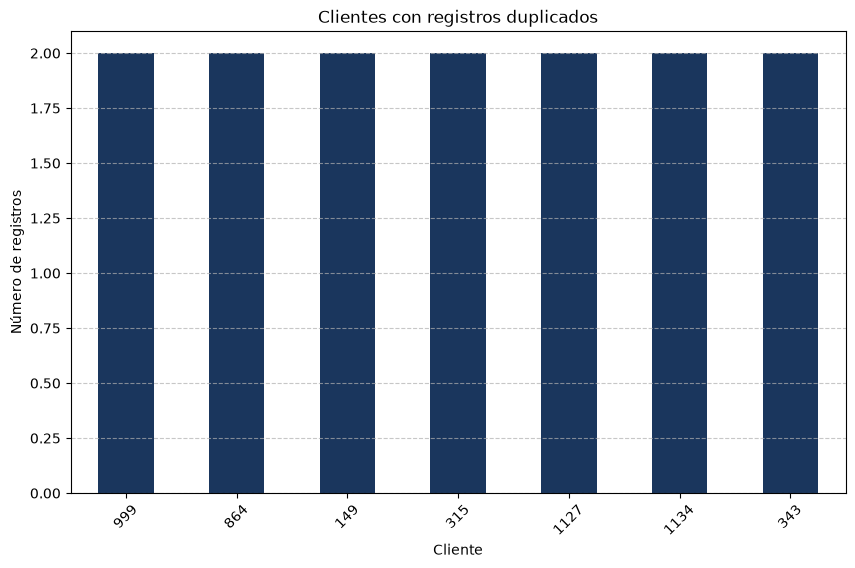

In [33]:
# Identificar clientes duplicados

conteo_clientes = df["Cliente"].value_counts()

clientes_duplicados = conteo_clientes[conteo_clientes > 1]

print("Clientes duplicados:")
print(clientes_duplicados)

print("\nCantidad de clientes duplicados:", len(clientes_duplicados))

# Gráfica de duplicidad
if not clientes_duplicados.empty:
    plt.figure(figsize=(10, 6))

    clientes_duplicados.plot(
        kind="bar",
        color=paleta_consultora[0]
    )

    plt.title("Clientes con registros duplicados")
    plt.xlabel("Cliente")
    plt.ylabel("Número de registros")
    plt.xticks(rotation=45)

    plt.grid(axis="y", linestyle="--", alpha=0.7)

    plt.show()
else:
    print("No se encontraron clientes duplicados para graficar.")

In [34]:
# Cantidad total de registros
total_registros = len(df)

# Cantidad de registros duplicados
registros_duplicados = df.duplicated().sum()

# Cantidad de clientes únicos
clientes_unicos = df["Cliente"].nunique()

# Cantidad de clientes con más de un registro
clientes_duplicados = (df["Cliente"].value_counts() > 1).sum()

print("Total de registros:", total_registros)
print("Registros completamente duplicados:", registros_duplicados)
print("Clientes únicos:", clientes_unicos)
print("Clientes con múltiples campos duplicados:", clientes_duplicados)

Total de registros: 1215
Registros completamente duplicados: 6
Clientes únicos: 1208
Clientes con múltiples campos duplicados: 7


In [35]:
# Eliminación de Registros Completamente Duplicados
print(f"Forma del DataFrame antes de eliminar duplicados: {df.shape}")

df_cleaned = df.drop_duplicates(keep='first')

print(f"Forma del DataFrame después de eliminar duplicados: {df_cleaned.shape}")

df = df_cleaned.copy()

Forma del DataFrame antes de eliminar duplicados: (1215, 27)
Forma del DataFrame después de eliminar duplicados: (1209, 27)


## R3 Edad

Se identificaron 12 registros con valores atípicos en la variable Edad, con registros superiores a 100 años, edades fuera del rango esperado (18-100 años).

Para su corrección se utilizó la mediana de las edades válidas, equivalente a 29 años, debido a que es una medida robusta frente a valores atípicos y evita que estos distorsionen la imputación. Los 12 valores inconsistentes fueron reemplazados por la mediana.

count    1209.000000
mean       44.576510
std       125.096437
min        19.000000
25%        26.000000
50%        29.000000
75%        38.000000
max      2000.000000
Name: Edad, dtype: float64

Edades inusuales:
      Cliente  Edad
113        22  1120
239      1115  2000
272       787  1000
535      1068  1280
637        41  1640
641      1158  1240
685       958  1120
735        26   880
787      1186  1080
1065       13  1160
1079     1169  1320
1172      158  1240

Cantidad de edades inusuales: 12


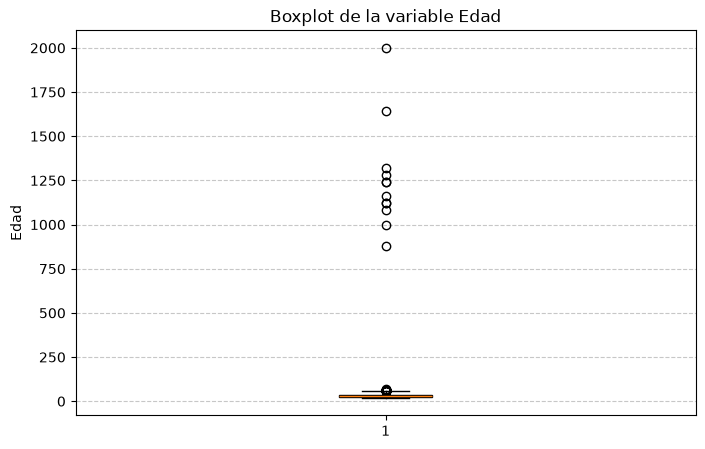

In [36]:
# Estadísticas de la variable Edad
print(df["Edad"].describe())

# Identificar edades fuera de un rango

edad_inusual = df[(df["Edad"] < 18) | (df["Edad"] > 100)]

print("\nEdades inusuales:")
print(edad_inusual[["Cliente", "Edad"]])

print("\nCantidad de edades inusuales:", len(edad_inusual))

# Boxplot de Edad

plt.figure(figsize=(8, 5))

plt.boxplot(df["Edad"].dropna(), boxprops=dict(facecolor=paleta_consultora[0]), patch_artist=True)

plt.title("Boxplot de la variable Edad")
plt.ylabel("Edad")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

In [37]:
# Identificar edades válidas
edades_validas = df.loc[
    df["Edad"].between(18, 100),
    "Edad"
]

# Calcular la mediana
mediana_edad = edades_validas.median()

print("Mediana de edad:", mediana_edad)

# Identificar edades incorrectas


condicion_edad = (df["Edad"] < 18) | (df["Edad"] > 100)

print("Edades incorrectas:", condicion_edad.sum())

# Reemplazar valores incorrectos

df.loc[condicion_edad, "Edad"] = mediana_edad

# Verificar resultado

print("\nEdades después de la corrección:")
print(df["Edad"].describe())

print("\nValores de edad fuera del rango:")
print(df[(df["Edad"] < 18) | (df["Edad"] > 100)][["Cliente", "Edad"]])

Mediana de edad: 29.0
Edades incorrectas: 12

Edades después de la corrección:
count    1209.000000
mean       32.391232
std         9.425376
min        19.000000
25%        26.000000
50%        29.000000
75%        37.000000
max        67.000000
Name: Edad, dtype: float64

Valores de edad fuera del rango:
Empty DataFrame
Columns: [Cliente, Edad]
Index: []


## R4 Creditos Vigentes

Se identificó un registro con 25 créditos vigentes, valor significativamente superior al comportamiento general de la variable. Sin embargo, al no contar con evidencia suficiente para determinar que corresponde a un error de registro, se conserva como un posible outlier.

Se excluye de los datos, pero no se eliman, teniendo como un maximo 5 de 5 creditos vigentes.


Distribución de créditos vigentes:
Numero de creditos vigentes
0     1098
1       87
2       20
3        1
4        2
25       1
Name: count, dtype: int64

Estadísticas descriptivas:
count    1209.000000
mean        0.134822
std         0.819376
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        25.000000
Name: Numero de creditos vigentes, dtype: float64

Q1: 0.0
Q3: 0.0
IQR: 0.0
Límite superior: 0.0


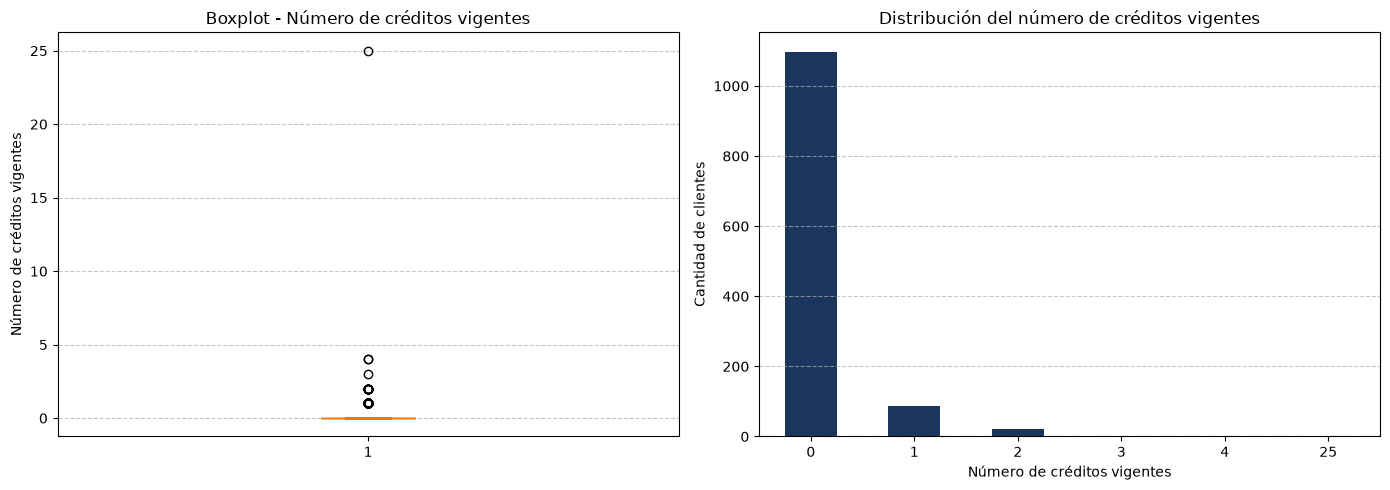

In [38]:
# Identificar outliers en numero de creditos
columna = "Numero de creditos vigentes"

# Distribución de la variable

print("Distribución de créditos vigentes:")
print(df[columna].value_counts().sort_index())

# Estadísticas descriptivas

print("\nEstadísticas descriptivas:")
print(df[columna].describe())

# Identificar valores potencialmente atípicos

Q1 = df[columna].quantile(0.25)
Q3 = df[columna].quantile(0.75)
IQR = Q3 - Q1

limite_superior = Q3 + (1.5 * IQR)

print("\nQ1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite superior:", limite_superior)

outliers = df[df[columna] > limite_superior]

# Crear los dos diagramas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot

axes[0].boxplot(df[columna], boxprops=dict(facecolor=paleta_consultora[0]), patch_artist=True)

axes[0].set_title("Boxplot - Número de créditos vigentes")
axes[0].set_ylabel("Número de créditos vigentes")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Gráfico de distribución

df[columna].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    color=paleta_consultora[0]
)

axes[1].set_title("Distribución del número de créditos vigentes")
axes[1].set_xlabel("Número de créditos vigentes")
axes[1].set_ylabel("Cantidad de clientes")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

# Ajustar espacios
plt.tight_layout()

# Mostrar gráficos
plt.show()

## Se Asigna la exlucion de maximo de creditos vigentes
# df = df[
#     df[columna] <= 5
# ].copy()

## R5 FDESEM

La variable FDESEM presentaba fechas almacenadas en diferentes formatos. Se realizó la conversión de la variable a un formato estándar de fecha (datetime), permitiendo homogeneizar los registros sin eliminar información. Posteriormente, se verificó la existencia de fechas que no pudieran ser convertidas.

In [39]:
# Convertir la columna FDESEM a formato datetime, manejando errores
df['FDESEM'] = pd.to_datetime(df['FDESEM'], errors='coerce', dayfirst=True)

# Contar valores nulos después de la conversión
nulos_fdesem = df['FDESEM'].isna().sum()
print(f"Cantidad de valores nulos o inválidos en FDESEM después de la conversión: {nulos_fdesem}")

# Formatear la columna FDESEM a 'dd/MM/YYYY' como string
df['FDESEM'] = df['FDESEM'].dt.strftime('%d/%m/%Y')

print('\nPrimeras 5 filas de la columna FDESEM después del formato:')
print(df['FDESEM'].head())

Cantidad de valores nulos o inválidos en FDESEM después de la conversión: 0

Primeras 5 filas de la columna FDESEM después del formato:
0    02/10/2013
1    08/05/2013
2    23/02/2015
3    16/12/2014
4    28/10/2015
Name: FDESEM, dtype: str


## R6 Tipo_Vivienda

La variable Tipo_Vivienda presentó 50 valores faltantes. Debido a que es una variable categórica, se decidió reemplazar los valores ausentes por la categoría SIN_INFORMACION, evitando imputarlos con una categoría existente y conservar así la ausencia de información como una categoría explícita.

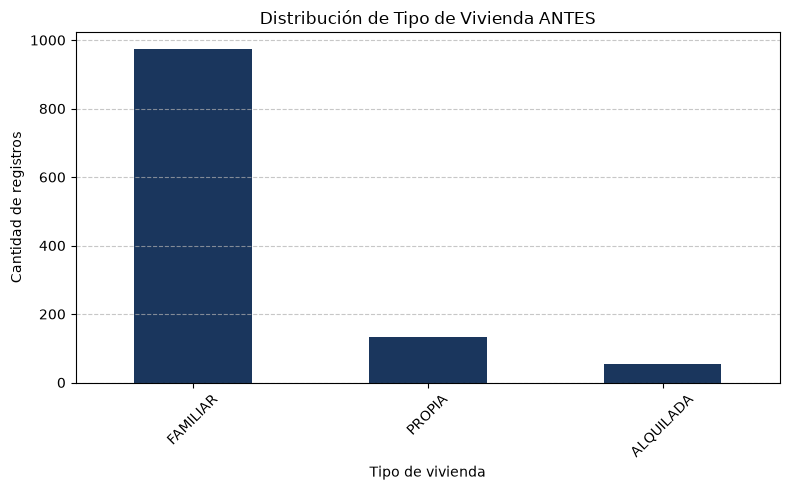

Valores faltantes antes:
50

Valores faltantes después:
0

Distribución de Tipo_Vivienda:
Tipo_Vivienda
FAMILIAR           974
PROPIA             132
ALQUILADA           53
SIN_INFORMACION     50
Name: count, dtype: int64


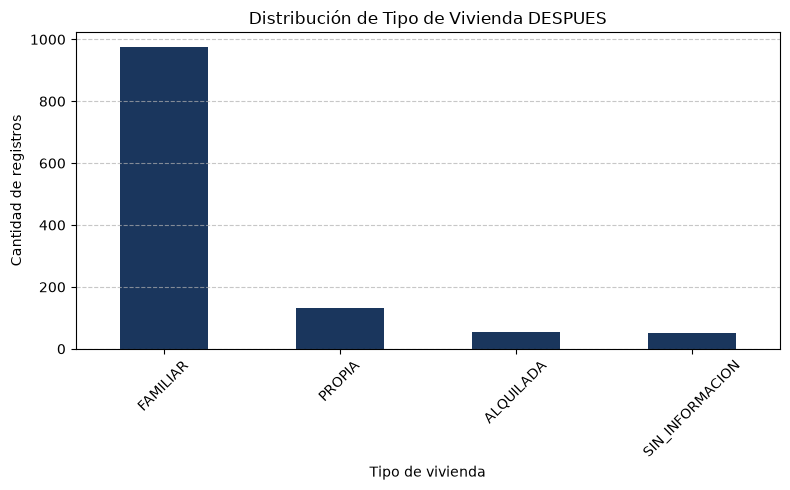

In [40]:
# Grafica antes de la creación de la nueva categoria para los valores nulos
plt.figure(figsize=(8, 5))

df["Tipo_Vivienda"].value_counts().plot(kind="bar", color=paleta_consultora[0])

plt.title("Distribución de Tipo de Vivienda ANTES")
plt.xlabel("Tipo de vivienda")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

###----------------------------------------------------------

# Revisar valores faltantes antes de la corrección
print("Valores faltantes antes:")
print(df["Tipo_Vivienda"].isna().sum())

# Crear la categoría "SIN_INFORMACION"
df["Tipo_Vivienda"] = df["Tipo_Vivienda"].fillna("SIN_INFORMACION")

# Verificar resultado
print("\nValores faltantes después:")
print(df["Tipo_Vivienda"].isna().sum())

# Ver distribución de categorías
print("\nDistribución de Tipo_Vivienda:")
print(df["Tipo_Vivienda"].value_counts())

###----------------------------------------------------------
# Grafica despues de la creación de la nueva categoria para los valores nulos

plt.figure(figsize=(8, 5))

df["Tipo_Vivienda"].value_counts().plot(kind="bar", color=paleta_consultora[0])

plt.title("Distribución de Tipo de Vivienda DESPUES")
plt.xlabel("Tipo de vivienda")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## R7 Sector

La variable `SECTOR` presentó 21 valores faltantes. Para su manejo, y dado que es una variable categórica, se imputarán los valores nulos con la categoría 'SIN_INFORMACION'. Esto permite preservar la información de ausencia de dato y evitar introducir sesgos por imputación con categorías existentes.

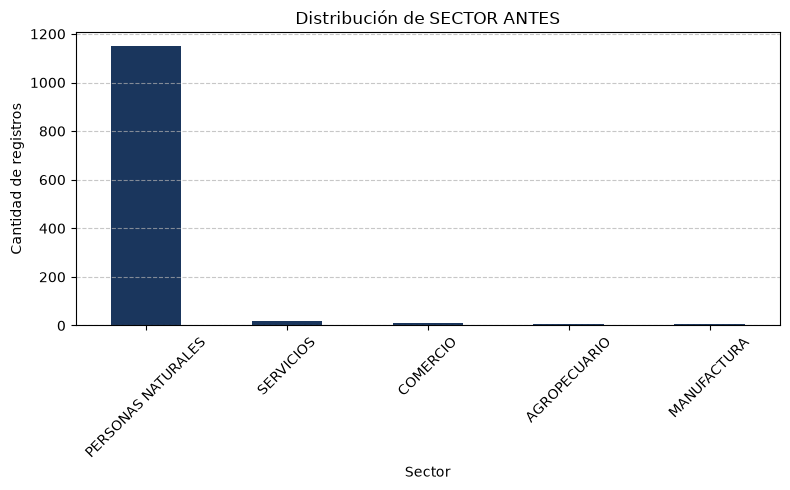

Valores faltantes antes:
21

Valores faltantes después:
0

Distribución de SECTOR:
SECTOR
PERSONAS NATURALES    1149
SIN_INFORMACION         21
SERVICIOS               19
COMERCIO                10
AGROPECUARIO             5
MANUFACTURA              5
Name: count, dtype: int64


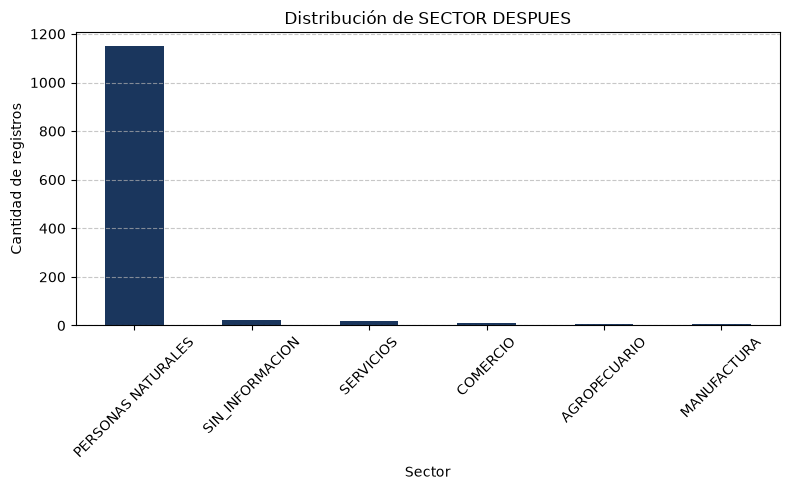

In [41]:
import matplotlib.pyplot as plt

# Grafica antes de la creación de la nueva categoria para los valores nulos
plt.figure(figsize=(8, 5))

df["SECTOR"].value_counts().plot(kind="bar", color=paleta_consultora[0])

plt.title("Distribución de SECTOR ANTES")
plt.xlabel("Sector")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

###----------------------------------------------------------

# Revisar valores faltantes antes de la corrección
print("Valores faltantes antes:")
print(df["SECTOR"].isna().sum())

# Crear la categoría "SIN_INFORMACION"
df["SECTOR"] = df["SECTOR"].fillna("SIN_INFORMACION")

# Verificar resultado
print("\nValores faltantes después:")
print(df["SECTOR"].isna().sum())

# Ver distribución de categorías
print("\nDistribución de SECTOR:")
print(df["SECTOR"].value_counts())

###----------------------------------------------------------
# Grafica despues de la creación de la nueva categoria para los valores nulos

plt.figure(figsize=(8, 5))

df["SECTOR"].value_counts().plot(kind="bar", color=paleta_consultora[0])

plt.title("Distribución de SECTOR DESPUES")
plt.xlabel("Sector")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## R8 Ingresos - Clasificacion y Segmentacion

Para el análisis de Ingresos, se aplicará un filtrado al **rango intercuartílico (entre el percentil 25 y el percentil 75)**. Esto se debe a que la mayor parte de la información relevante se concentra en este rango, mientras que los valores fuera de él (considerados observaciones atípicas u 'outliers') pueden distorsionar el análisis y se interpretan como casos excepcionales dentro de la distribución.

Cuartiles de Ingresos: P25=0.9,P50=1.144668,P75=1.26,P90=1.3257312


c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


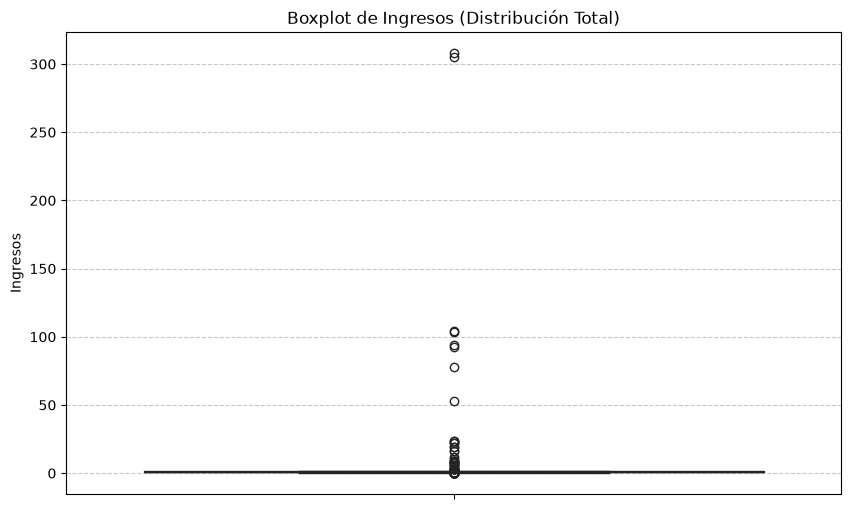

c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


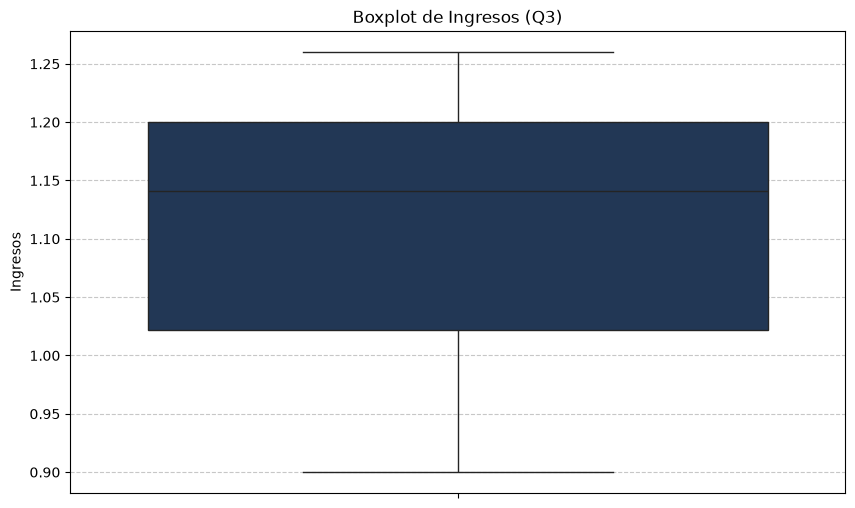

Total Numero de de Registros: 1209.00
Total de registros del Q3: 616.00
Diferencia (Total - Q3): 593.00


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Asegurarse de que la columna 'Ingresos' sea numérica
df['Ingresos'] = pd.to_numeric(df['Ingresos'], errors='coerce')

# Eliminar filas con valores nulos en 'Ingresos' si los hubiera, para el cálculo de cuartiles
df_ingresos_cleaned = df.dropna(subset=['Ingresos']).copy()

# Calcular los persentiles de la columna 'Ingresos'
P25,P50,P75,P90 = np.percentile(df_ingresos_cleaned['Ingresos'], [25, 50, 75,90])

print(f"Cuartiles de Ingresos: P25={P25},P50={P50},P75={P75},P90={P90}")

# --- Gráfico 1: Boxplot de 'Ingresos' total ---
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_ingresos_cleaned,
    y='Ingresos',
    color=paleta_consultora[0]
)
plt.title('Boxplot de Ingresos (Distribución Total)')
plt.ylabel('Ingresos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# --- Gráfico 2: Boxplot Q3 de 'Ingresos' ---
df_q3 = df_ingresos_cleaned[
   (df_ingresos_cleaned['Ingresos'] >= P25) & (df_ingresos_cleaned['Ingresos'] <= P75)
  ].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_q3,
    y='Ingresos',
    color=paleta_consultora[0]
)
plt.title('Boxplot de Ingresos (Q3)')
plt.ylabel('Ingresos')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calcular la suma total de ingresos y la suma de ingresos hasta Q3
total_ingresos_count = df_ingresos_cleaned['Ingresos'].count()
diferencia = total_ingresos_count - df_q3['Ingresos'].count()

print(f"Total Numero de de Registros: {total_ingresos_count:.2f}")
print(f"Total de registros del Q3: {df_q3['Ingresos'].count():.2f}")
print(f"Diferencia (Total - Q3): {diferencia:.2f}")

## Actualiza la DF con la informacion de Q3
#df = df_q3.copy()

## Boxplots Posterior a limpieza

c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Proyects\TallerIA\venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'hori

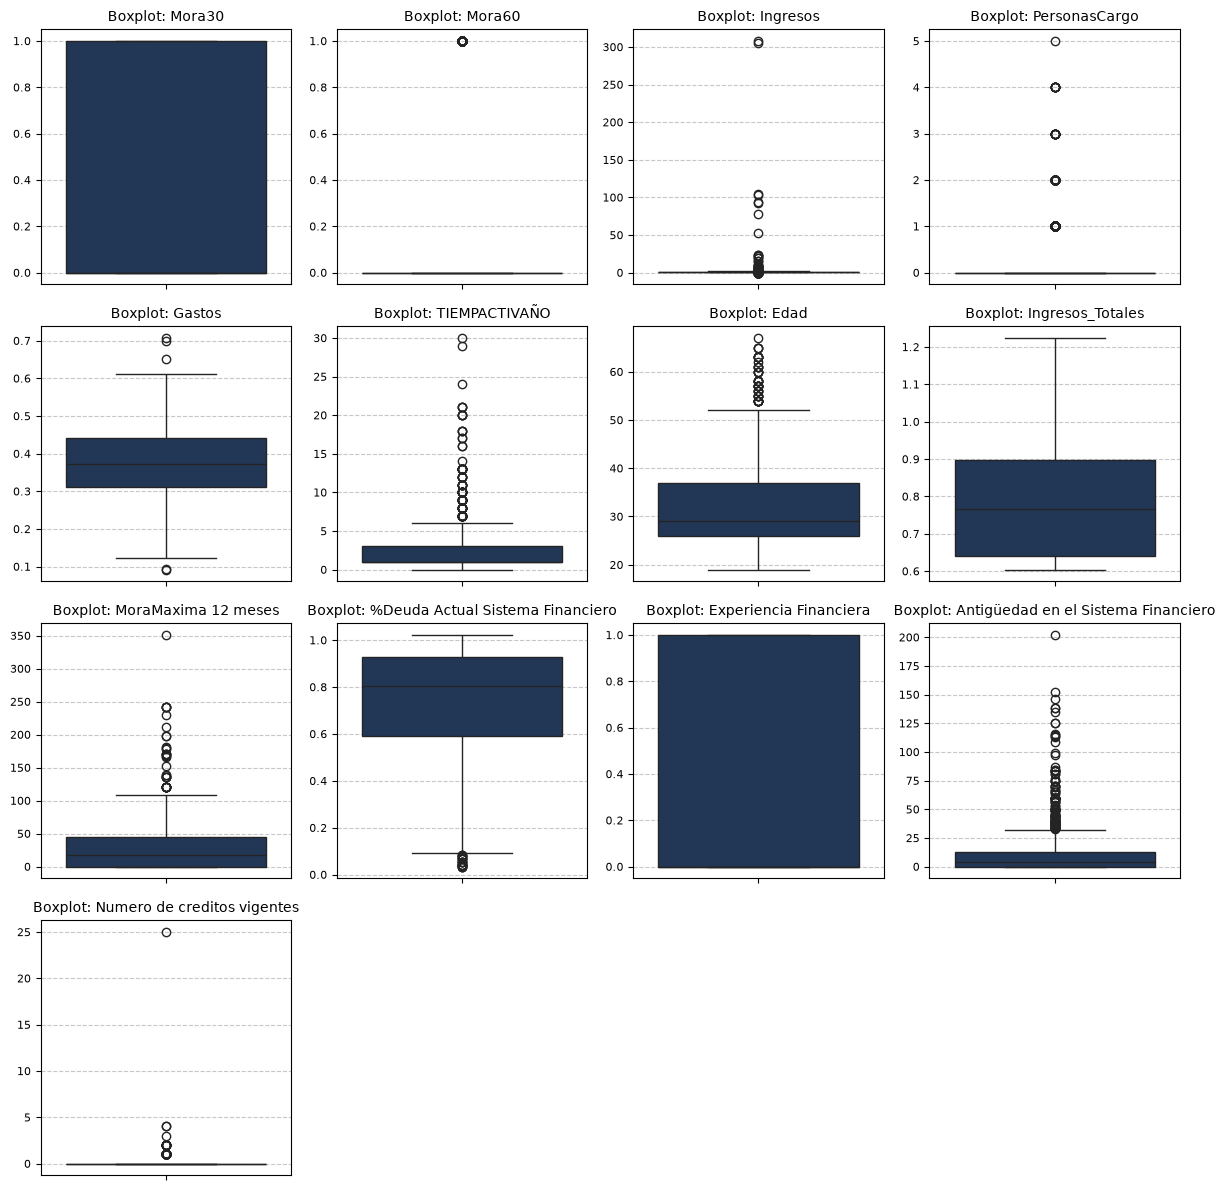

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Seleccionar solo las columnas numéricas
numerical_cols = df.select_dtypes(include=['number']).columns

# Excluir la columna 'Cliente' si es numérica, ya que generalmente es un ID y no se presta para boxplots significativos.
if 'Cliente' in numerical_cols:
    numerical_cols = numerical_cols.drop('Cliente')

# Calcular el número de filas y columnas para la matriz de boxplots
num_plots = len(numerical_cols)
num_cols = 4 # Número deseado de columnas en la cuadrícula
num_rows = int(np.ceil(num_plots / num_cols))

plt.figure(figsize=(num_cols * 3, num_rows * 3)) # Ajustar el tamaño total de la figura

for i, column in enumerate(numerical_cols):
    plt.subplot(num_rows, num_cols, i + 1) # Crear un subplot para cada columna
    sns.boxplot(y=df[column].dropna(), color=paleta_consultora[0])
    plt.title(f'Boxplot: {column}', fontsize=10)
    plt.ylabel('') # Ocultar etiqueta y para no saturar
    plt.tick_params(axis='y', labelsize=8) # Reducir tamaño de ticks
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout() # Ajustar el diseño para evitar superposiciones
plt.show()

# 5- Análisis descriptivo

## Tasa de Mora 30 y 60

In [44]:
import pandas as pd

# Asegurarse de que las columnas de mora sean numéricas
df['Mora30'] = pd.to_numeric(df['Mora30'], errors='coerce')
df['Mora60'] = pd.to_numeric(df['Mora60'], errors='coerce')

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Segmento'
mora_por_segmento = df.groupby('Segmento')[['Mora30', 'Mora60']].mean().reset_index()
print("Tasa de Mora por Segmento:")
display(mora_por_segmento)

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Calificación Superfinanciera'
mora_por_calificacion = df.groupby('Calificación Superfinanciera')[['Mora30', 'Mora60']].mean().reset_index()
print("\nTasa de Mora por Calificación Superfinanciera:")
display(mora_por_calificacion)

# Calcular la tasa de mora para 30 y 60 días agrupado por 'Segmento' y 'Calificación Superfinanciera'
mora_segmento_calificacion = df.groupby(['Segmento', 'Calificación Superfinanciera'])[['Mora30', 'Mora60']].mean().reset_index()
print("\nTasa de Mora por Segmento y Calificación Superfinanciera:")
display(mora_segmento_calificacion)

Tasa de Mora por Segmento:


,Segmento,Mora30,Mora60
0,MDO,0.250620,0.115385
1,MPY,0.470588,0.058824
2,PY,0.272727,0.000000
3,STD,0.299065,0.124611
4,VIP,0.166667,0.129630



Tasa de Mora por Calificación Superfinanciera:


,Calificación Superfinanciera,Mora30,Mora60
0,A,0.263793,0.118103
1,B,0.357143,0.214286
2,C,0.111111,0.000000
3,D,0.400000,0.066667
4,E,0.000000,0.000000



Tasa de Mora por Segmento y Calificación Superfinanciera:


,Segmento,Calificación Superfinanciera,Mora30,Mora60
0,MDO,A,0.249680,0.117798
1,MDO,B,0.166667,0.166667
2,MDO,C,0.333333,0.000000
3,MDO,D,0.555556,0.000000
4,MDO,E,0.000000,0.000000
5,MPY,A,0.470588,0.058824
6,PY,A,0.111111,0.000000
7,PY,B,1.000000,0.000000
8,STD,A,0.311037,0.123746
9,STD,B,0.333333,0.333333


## Escenario Probabilisiticos

## Por Calificacion

¿ Cuál es la probabilidad de que un cliente con calificación C, D o E entre en mora,
comparado con uno calificado A o B ?

In [45]:
# Calcular la probabilidad de Mora30 para clientes con calificación A o B
calificaciones_ab = ['A', 'B']
prob_mora_ab = df[df['Calificación Superfinanciera'].isin(calificaciones_ab)]['Mora30'].mean()

# Calcular la probabilidad de Mora30 para clientes con calificación C, D o E
calificaciones_cde = ['C', 'D', 'E']
prob_mora_cde = df[df['Calificación Superfinanciera'].isin(calificaciones_cde)]['Mora30'].mean()

print(f"Probabilidad de Mora30 para clientes con calificación A o B: {prob_mora_ab:.2%}")
print(f"Probabilidad de Mora30 para clientes con calificación C, D o E: {prob_mora_cde:.2%}")

# Comparación
if prob_mora_ab > prob_mora_cde:
    print(f"\nLos clientes con calificación A o B tienen una probabilidad {prob_mora_ab - prob_mora_cde:.2%} mayor de entrar en mora30 que los de calificación C, D o E.")
elif prob_mora_cde > prob_mora_ab:
    print(f"\nLos clientes con calificación C, D o E tienen una probabilidad {prob_mora_cde - prob_mora_ab:.2%} mayor de entrar en mora30 que los de calificación A o B.")
else:
    print("\nLa probabilidad de Mora30 es similar para ambos grupos de calificación.")

Probabilidad de Mora30 para clientes con calificación A o B: 26.49%
Probabilidad de Mora30 para clientes con calificación C, D o E: 20.00%

Los clientes con calificación A o B tienen una probabilidad 6.49% mayor de entrar en mora30 que los de calificación C, D o E.


## Por Experiencia Financiera

¿Qué tan probable es que un cliente sin experiencia financiera previa
(Experiencia_Financiera = 0) caiga en mora, frente a uno que ya tenía historial?

In [46]:
# Asegurarse de que la columna 'Experiencia Financiera' sea numérica
df['Experiencia Financiera'] = pd.to_numeric(df['Experiencia Financiera'], errors='coerce')

# Calcular la probabilidad de Mora30 para clientes sin experiencia financiera (0)
prob_mora_sin_experiencia = df[df['Experiencia Financiera'] == 0]['Mora30'].mean()

# Calcular la probabilidad de Mora30 para clientes con experiencia financiera (1)
prob_mora_con_experiencia = df[df['Experiencia Financiera'] == 1]['Mora30'].mean()

print(f"Probabilidad de Mora30 para clientes SIN experiencia financiera: {prob_mora_sin_experiencia:.2%}")
print(f"Probabilidad de Mora30 para clientes CON experiencia financiera: {prob_mora_con_experiencia:.2%}")

# Comparación
if prob_mora_sin_experiencia > prob_mora_con_experiencia:
    print(f"\nLos clientes SIN experiencia financiera tienen una probabilidad {prob_mora_sin_experiencia - prob_mora_con_experiencia:.2%} mayor de entrar en mora30 que los CON experiencia financiera.")
elif prob_mora_con_experiencia > prob_mora_sin_experiencia:
    print(f"\nLos clientes CON experiencia financiera tienen una probabilidad {prob_mora_con_experiencia - prob_mora_sin_experiencia:.2%} mayor de entrar en mora30 que los SIN experiencia financiera.")
else:
    print("\nLa probabilidad de Mora30 es similar para ambos grupos de experiencia financiera.")

Probabilidad de Mora30 para clientes SIN experiencia financiera: 28.91%
Probabilidad de Mora30 para clientes CON experiencia financiera: 21.34%

Los clientes SIN experiencia financiera tienen una probabilidad 7.57% mayor de entrar en mora30 que los CON experiencia financiera.


## Por Cantidad de Creditos Vigentes

¿Existe relación entre el número de créditos vigentes y la probabilidad de mora?


Probabilidad de Mora30 por Número de Créditos Vigentes:


,Numero de creditos vigentes,Probabilidad_Mora30
0,0,0.265027
1,1,0.241379
2,2,0.300000
3,3,0.000000
4,4,0.000000
5,25,0.000000


C:\Users\jhona\AppData\Local\Temp\ipykernel_11560\875914930.py:13: UserWarning: 
The palette list has fewer values (4) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x='Numero de creditos vigentes', y='Probabilidad_Mora30', data=prob_mora_por_creditos, hue='Numero de creditos vigentes', palette=paleta_consultora, legend=False)


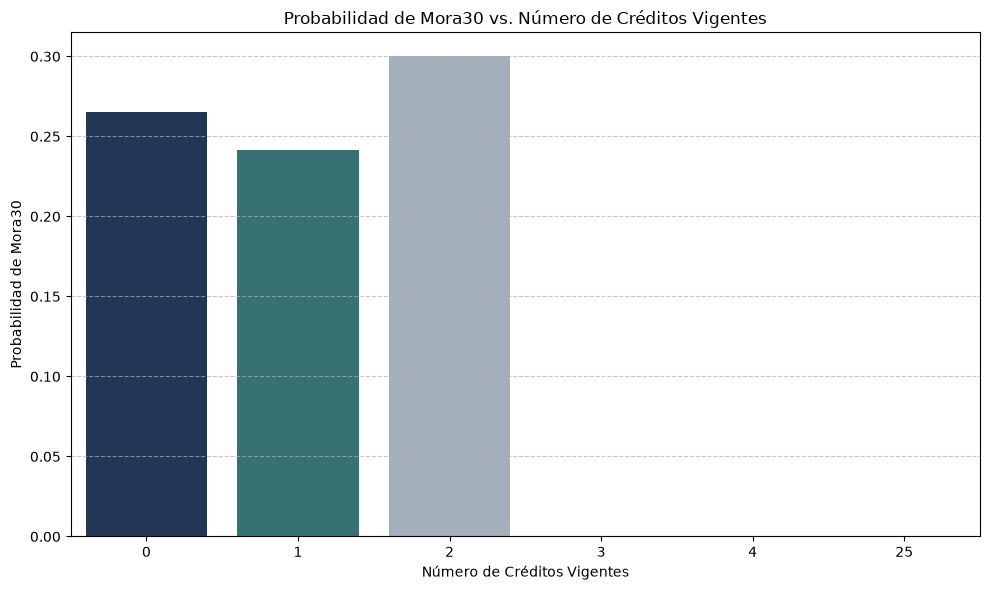

In [47]:
# Calcular la probabilidad de Mora30 para cada número de créditos vigentes
prob_mora_por_creditos = df.groupby('Numero de creditos vigentes')['Mora30'].mean().reset_index()
prob_mora_por_creditos.rename(columns={'Mora30': 'Probabilidad_Mora30'}, inplace=True)

print("Probabilidad de Mora30 por Número de Créditos Vigentes:")
display(prob_mora_por_creditos)

# Definir la paleta de colores de la consultora
paleta_consultora = ['#1A365D', '#2C7A7B', '#A0AEC0', '#4FD1C5']

# Visualizar la relación
plt.figure(figsize=(10, 6))
sns.barplot(x='Numero de creditos vigentes', y='Probabilidad_Mora30', data=prob_mora_por_creditos, hue='Numero de creditos vigentes', palette=paleta_consultora, legend=False)
plt.title('Probabilidad de Mora30 vs. Número de Créditos Vigentes')
plt.xlabel('Número de Créditos Vigentes')
plt.ylabel('Probabilidad de Mora30')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
# Inicio Entregamiento de Datos

In [48]:
# Definir la variable objetivo y las columnas que deben excluirse
import janitor as jn
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

objetivo = "mora30"
cols_leake = [
    "segmento",
    "sector",
    "regcons",
]
excluir = [
    "cliente",
    "mora30",
    "mora60",
    "fdesem"
] + cols_leake

df = jn.clean_names(df)

x = df.drop(columns=excluir)
y = df[objetivo]

print("Forma de X:", x.shape)
print("Media de y:", y.mean())
print("Conteo de tipos de datos en X:")
print(x.dtypes.value_counts())

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print("Forma de X_train:", x_train.shape)
print("Forma de X_test:", x_test.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de y_test:", y_test.shape)

modelo_tonto = DummyClassifier(strategy="most_frequent")
modelo_tonto.fit(x_train, y_train)
print("Modelo DummyClassifier entrenado correctamente.")

predicciones_tonto = modelo_tonto.predict(x_test)
exactitud_tonto = accuracy_score(y_test, predicciones_tonto)
print("Accuracy del DummyClassifier:", exactitud_tonto)

matriz_confusion_tonto = confusion_matrix(y_test, predicciones_tonto)
print("Matriz de confusión del DummyClassifier:")
print(matriz_confusion_tonto)

Forma de X: (1209, 20)
Media de y: 0.2630272952853598
Conteo de tipos de datos en X:
str        8
int64      6
float64    5
object     1
Name: count, dtype: int64
Forma de X_train: (967, 20)
Forma de X_test: (242, 20)
Forma de y_train: (967,)
Forma de y_test: (242,)
Modelo DummyClassifier entrenado correctamente.
Accuracy del DummyClassifier: 0.7355371900826446
Matriz de confusión del DummyClassifier:
[[178   0]
 [ 64   0]]


---

In [49]:
# Seleccionar las variables numéricas disponibles después de aplicar clean_names
columnas_excluidas = {"cliente", "mora30", "mora60"}
variables_numericas = [
    columna
    for columna in df.select_dtypes(include="number").columns
    if columna not in columnas_excluidas
]

X = df[variables_numericas].copy()
print("Variables numéricas seleccionadas:", variables_numericas)
print("Valores nulos por variable:")
print(X.isnull().sum())
display(X.describe().T)

Variables numéricas seleccionadas: ['ingresos', 'personascargo', 'gastos', 'tiempactivano', 'edad', 'ingresos_totales', 'moramaxima_12_meses', '%deuda_actual_sistema_financiero', 'experiencia_financiera', 'antiguedad_en_el_sistema_financiero', 'numero_de_creditos_vigentes']
Valores nulos por variable:
ingresos                                0
personascargo                          50
gastos                                  0
tiempactivano                           0
edad                                    0
ingresos_totales                        0
moramaxima_12_meses                     0
%deuda_actual_sistema_financiero        0
experiencia_financiera                  0
antiguedad_en_el_sistema_financiero     0
numero_de_creditos_vigentes             0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
ingresos,1209.0,2.165673,13.964540,0.000000,0.900000,1.144668,1.260000,308.000000
personascargo,1159.0,0.335634,0.720079,0.000000,0.000000,0.000000,0.000000,5.000000
gastos,1209.0,0.387957,0.081877,0.091945,0.310388,0.372420,0.441324,0.707305
tiempactivano,1209.0,2.588089,3.304481,0.000000,1.000000,1.000000,3.000000,30.000000
edad,1209.0,32.391232,9.425376,19.000000,26.000000,29.000000,37.000000,67.000000
ingresos_totales,1209.0,0.787005,0.153722,0.604185,0.641000,0.765000,0.896000,1.224009
moramaxima_12_meses,1209.0,26.109181,36.213582,0.000000,0.000000,17.000000,45.000000,351.000000
%deuda_actual_sistema_financiero,1209.0,0.727738,0.250616,0.034204,0.591965,0.803806,0.928166,1.022126
experiencia_financiera,1209.0,0.344913,0.475537,0.000000,0.000000,0.000000,1.000000,1.000000
antiguedad_en_el_sistema_financiero,1209.0,11.551696,20.657348,0.000000,0.000000,4.000000,13.000000,202.000000


¿Por qué Cliente no está en la lista? ¿Por qué Mora30 tampoco?

Por que la variable cliente puede permitir que genenere grupos por su relacion con los datos. y la mora30 es la variable objetivo, y puede hacer que el modelo se aprenda las respuestas y quede `Sobre Ajustado`

In [56]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd

imputador = SimpleImputer(strategy="median")
X_imputado = imputador.fit_transform(X)

scaler = StandardScaler()
X_esc = scaler.fit_transform(X_imputado)

pd.DataFrame(X_esc, columns=variables_numericas).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ingresos,1209.0,0.0,1.0,-0.16,-0.09,-0.07,-0.06,21.91
personascargo,1209.0,-0.0,1.0,-0.45,-0.45,-0.45,-0.45,6.61
gastos,1209.0,0.0,1.0,-3.62,-0.95,-0.19,0.65,3.90
tiempactivano,1209.0,0.0,1.0,-0.78,-0.48,-0.48,0.12,8.30
edad,1209.0,0.0,1.0,-1.42,-0.68,-0.36,0.49,3.67
ingresos_totales,1209.0,-0.0,1.0,-1.19,-0.95,-0.14,0.71,2.84
moramaxima_12_meses,1209.0,0.0,1.0,-0.72,-0.72,-0.25,0.52,8.98
%deuda_actual_sistema_financiero,1209.0,0.0,1.0,-2.77,-0.54,0.30,0.80,1.18
experiencia_financiera,1209.0,-0.0,1.0,-0.73,-0.73,-0.73,1.38,1.38
antiguedad_en_el_sistema_financiero,1209.0,0.0,1.0,-0.56,-0.56,-0.37,0.07,9.22


In [57]:
from sklearn.cluster import KMeans

kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
etiquetas3 = kmeans3.fit_predict(X_esc)

pd.Series(etiquetas3).value_counts().sort_index()

0    442
1    765
2      2
Name: count, dtype: int64

In [ ]:
centroides = scaler.inverse_transform(kmeans3.cluster_centers_)
tabla_centroides = pd.DataFrame(centroides, columns=variables_numericas).round(1)
tabla_centroides["n_clientes"] = pd.Series(etiquetas3).value_counts().sort_index().values
tabla_centroides

# Cluster 0 - 
# Cluster 1
# Cluster 2


,ingresos,personascargo,gastos,tiempactivano,edad,ingresos_totales,moramaxima_12_meses,%deuda_actual_sistema_financiero,experiencia_financiera,antiguedad_en_el_sistema_financiero,numero_de_creditos_vigentes,n_clientes
0,1.2,0.4,0.5,2.9,32.9,0.9,26.1,0.8,0.4,16.4,0.2,442
1,2.0,0.3,0.3,2.4,32.1,0.7,26.1,0.7,0.3,8.6,0.1,765
2,306.6,2.0,0.3,1.0,29.0,0.6,29.0,0.2,0.0,83.0,0.0,2
